In [186]:
import numpy as np
from langchain_ollama import ChatOllama
from rag_flow import RAGFlow
import pandas as pd
from time import perf_counter
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import requests
import math

from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

This file focuses on classifier llm evaluation. I am using langchain ollama library to simplify usage of two different models. I will compare accuracy, precision and recall, as well as running time between qwen3:8b and llama3.2:3b. I use synthetically created by ChatGPT balanced test data set consisting of 300 questions for evalution.

In [150]:
response = requests.get("http://localhost:11434/api/tags")
models = response.json()["models"]

for model in models:
    print(f"{model['name']}: {model['size'] / 1024**3:.2f} GB")

qwen3:8b: 4.87 GB
llama3.2:3b: 1.88 GB
nomic-embed-text:latest: 0.26 GB
gpt-oss:20b: 12.85 GB


In [151]:
evaluation_df = pd.DataFrame({
    "qwen" : {
        "accuracy": None,
        "precision": None,
        "recall": None,
        "mean_latency": None
    },
    "llama": {
        "accuracy": None,
        "precision": None,
        "recall": None,
        "mean_latency": None
    }
})

In [152]:
df = pd.read_csv("test_data/arxiv_classifier_300_questions.csv")
print(df["label"].value_counts())
df.head(3)

label
arxiv        150
not_valid    150
Name: count, dtype: int64


,question,label,source,difficulty,topic
0,What are the main limitations of economic growth models?,arxiv,synthetic,easy,economics
1,What are some practical tips for a neighborhood barbecue?,not_valid,synthetic,easy,everyday
2,What are the main limitations of operating system scheduling?,arxiv,synthetic,easy,computer science


In [153]:
qwen = ChatOllama(
    model="qwen3:8b",
    base_url="http://localhost:11434"
)

llama = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434"
)
models = {"qwen": qwen, "llama": llama}

In [154]:
for key, model in models.items():
    params = {
        "query_model": llama, # we don't care about these params, This is just a placeholder.
        "answer_model": llama, # we don't care about these params, This is just a placeholder
        "titles_limit": 5,
        "top_k_titles": 5,
        "chunk_size": 200,
        "chunk_overlap_fraction": 0.2,
        "top_k_chunks": 5,
        "candidate_k": 20,
        "classifier": model
    }
    qwen_rag = RAGFlow(params)
    classes = []
    latencies = []
    for q in df["question"]:
        start = perf_counter()
        classes.append(qwen_rag._classify_promt(q))
        latency = perf_counter() - start
        latencies.append(latency)
    df[f"{key}_prediction"] = classes
    df[f"{key}_latency"] = latencies

2026-10-13 23:22:02,824 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:22:06,677 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:22:17,153 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:22:23,222 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:22:31,308 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:22:39,220 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:22:46,853 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:22:53,380 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:23:00,944 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-13 23:23:10,479 | INFO | HTTP Request: POST http://localhost:11434/api/cha

Qwen somtimes generates answers as stings instead of returning only a number. I need to add a check of the answers returned by the llms are valid.

In [187]:
def validate_prediction(response):
    try:
        score = float(response)
        return score if math.isfinite(score) and 0 <= score <= 1 else np.nan
    except (ValueError, TypeError):
        return np.nan

In [189]:
df["qwen_prediction"] = df["qwen_prediction"].apply(validate_prediction)
df["llama_prediction"] = df["llama_prediction"].apply(validate_prediction)

In [208]:
print(f"{len(df[df["qwen_prediction"].isna()])} invalid predictions by qwen")
print(f"{len(df[df["llama_prediction"].isna()])} invalid predictions by llama")

1 invalid predictions by qwen
0 invalid predictions by llama


In [209]:
def plot_performance(eval_df, t):
    models = eval_df.columns
    x = np.arange(len(models))
    width = 0.25

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(x - width, eval_df.loc["accuracy"], width, label="Accuracy")
    ax.bar(x, eval_df.loc["precision"], width, label="Precision")
    ax.bar(x + width, eval_df.loc["recall"], width, label="Recall")

    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_ylabel("Score")
    ax.set_title(f"Models performace at threshold = {t}")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.grid(True)

    plt.show()

In [210]:
def calculate_scores_at(t):
    y_q_pred = (df["qwen_prediction"] > t).astype(int)
    y_l_pred = (df["llama_prediction"] > t).astype(int)

    evaluation_df.loc["accuracy", "qwen"] = accuracy_score(y_true, y_q_pred)
    evaluation_df.loc["accuracy", "llama"] = accuracy_score(y_true, y_l_pred)

    evaluation_df.loc["precision", "qwen"] = precision_score(y_true, y_q_pred)
    evaluation_df.loc["precision", "llama"] = precision_score(y_true, y_l_pred)

    evaluation_df.loc["recall", "qwen"] = recall_score(y_true, y_q_pred)
    evaluation_df.loc["recall", "llama"] = recall_score(y_true, y_l_pred)

    evaluation_df.loc["mean_latency", "qwen"] = np.mean(df["qwen_latency"])
    evaluation_df.loc["mean_latency", "llama"] = np.mean(df["llama_latency"])
    return evaluation_df

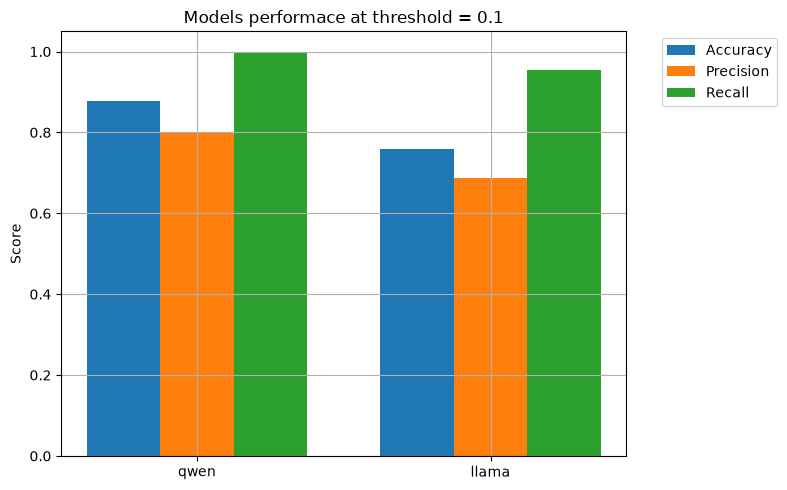

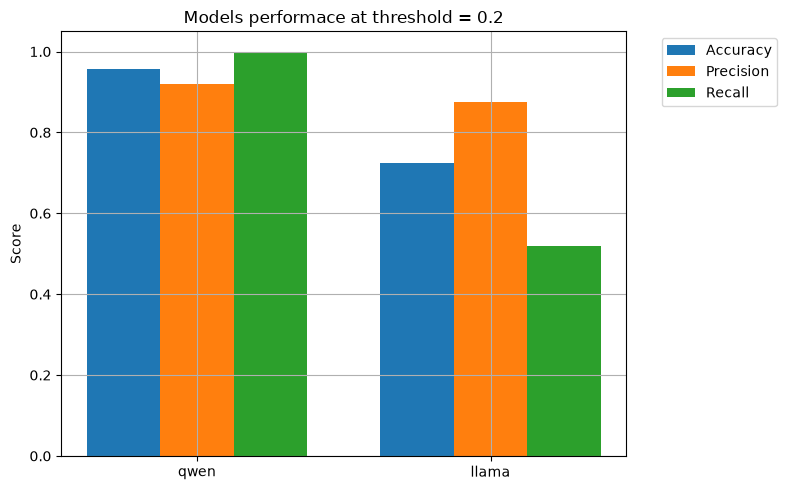

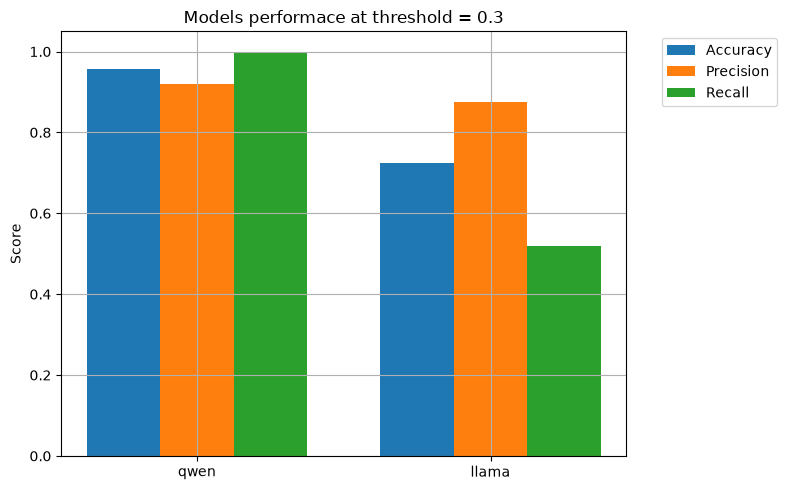

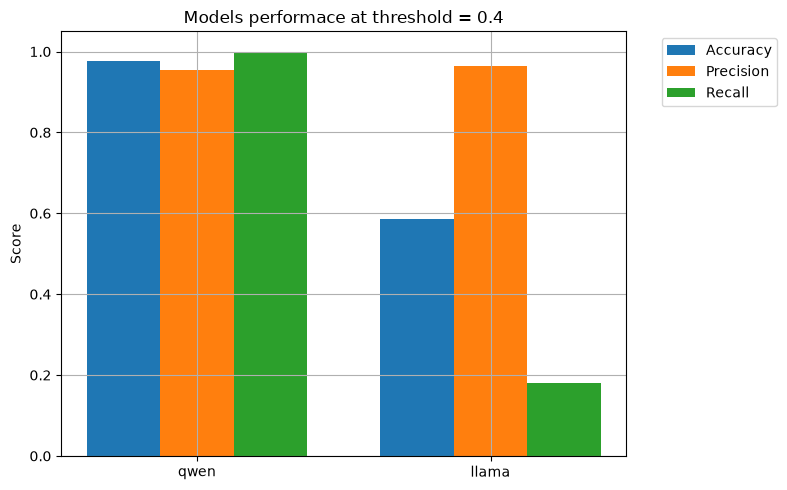

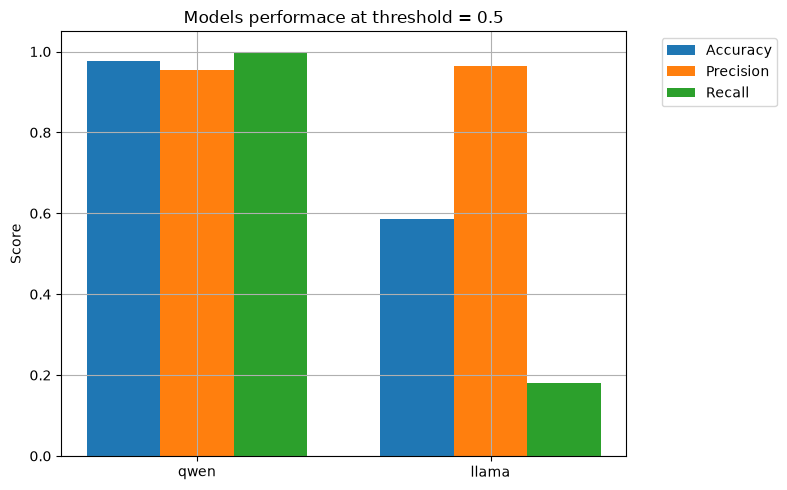

In [212]:
y_true = df["label"].map({
    "arxiv": 1,
    "not_valid": 0
})
threshold = [0.1, 0.2, 0.3, 0.4 ,0.5]
df["qwen_prediction"] = pd.to_numeric(df["qwen_prediction"])
df["llama_prediction"] = pd.to_numeric(df["llama_prediction"])
for t in threshold:
    evaluation_df = calculate_scores_at(t)
    plot_performance(evaluation_df, t)


From the graphs above, we can see that Qwen's scores remain relatively consistent across different thresholds and outperforms Llama. However, Llama performs substantially better at the lowest threshold of 0.1, particularly in terms of recall.

Considering that my RAG system already has several latency bottlenecks, I believe it would be more practical to choose a significantly faster model for the classification task, even at the cost of a some reduction in classification quality.

**_Conclusion_:** Llama model will be chosen for the classification task.

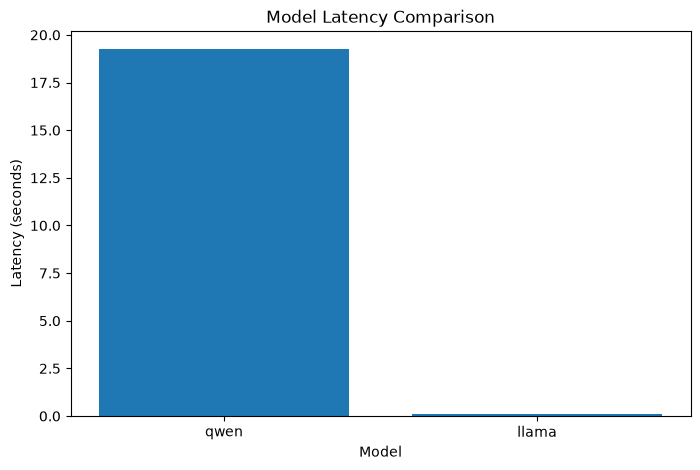

In [213]:
plt.figure(figsize=(8, 5))
plt.bar(evaluation_df.columns, evaluation_df.loc["mean_latency"])
plt.xlabel("Model")
plt.ylabel("Latency (seconds)")
plt.title("Model Latency Comparison")
plt.show()


In [214]:
# Added temperature=0 and few-shot examples to the system prompt.
new_llama = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=15,
    reasoning=False,
    num_ctx=3000,
)

params = {
    "query_model": qwen,
    "answer_model": qwen,
    "titles_limit": 5,
    "top_k_titles": 5,
    "chunk_size": 200,
    "chunk_overlap_fraction": 0.2,
    "candidate_k": 20,
    "top_k_chunks": 10,
    "classifier": new_llama
}

new_llama_rag = RAGFlow(params)

new_llama_results = []
new_llama_latencies = []

for q in df["question"]:
    start = perf_counter()

    prediction = new_llama_rag._classify_promt(q)

    latency = perf_counter() - start

    new_llama_results.append(prediction.strip().lower())
    new_llama_latencies.append(latency)

df["new_llama_prediction"] = pd.to_numeric(new_llama_results)
df["new_llama_latency"] = new_llama_latencies

2026-10-14 14:47:48,929 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,012 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,092 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,170 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,249 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,329 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,410 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,504 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,583 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-14 14:47:49,664 | INFO | HTTP Request: POST http://localhost:11434/api/cha

In [215]:
evaluation_df = calculate_scores_at(0.1)




In [217]:
new_llama_pred = (df["new_llama_prediction"] > 0.1).astype(int)

evaluation_df.loc["accuracy", "new_llama"] = accuracy_score(y_true, new_llama_pred)
evaluation_df.loc["precision", "new_llama"] = precision_score(y_true, new_llama_pred)
evaluation_df.loc["recall", "new_llama"] = recall_score(y_true, new_llama_pred)
evaluation_df.loc["mean_latency", "new_llama"] = np.mean(df["new_llama_latency"])


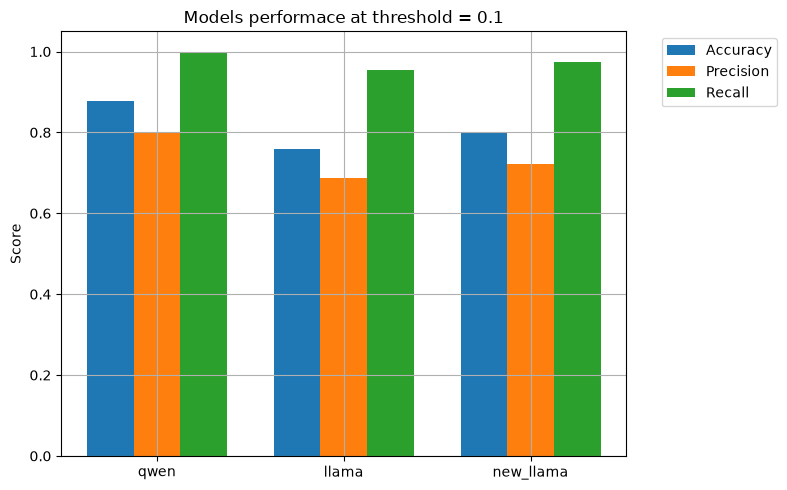

In [218]:
plot_performance(evaluation_df, 0.1)

Comparing thress models at threshhold 0.1, we see that the llama with explicitly set params
```
temperature=0,
num_predict=15,
reasoning=False,
num_ctx=3000,
```
performed slightly better on accuracy than Llama with default params.

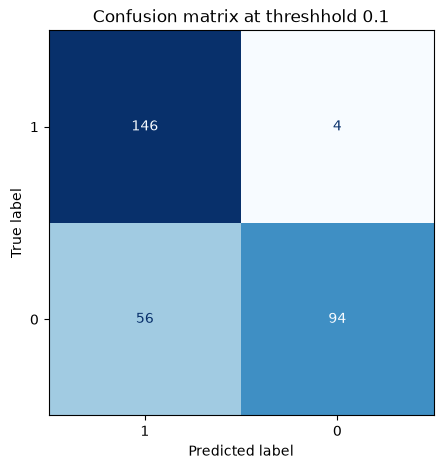

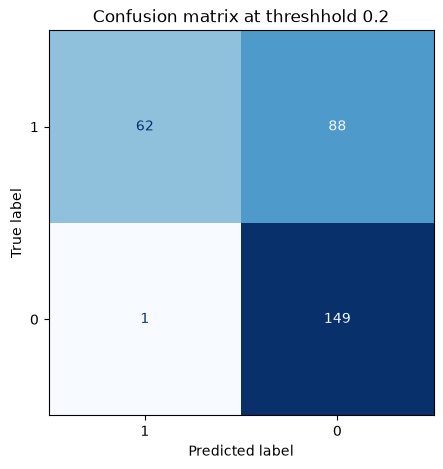

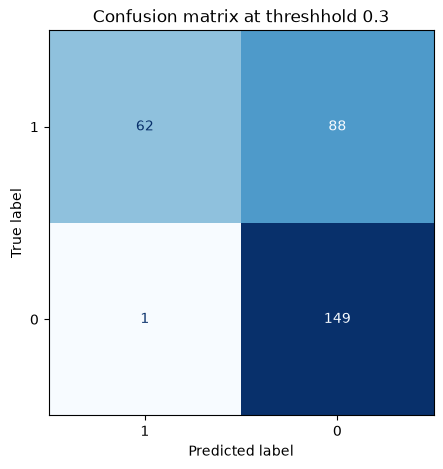

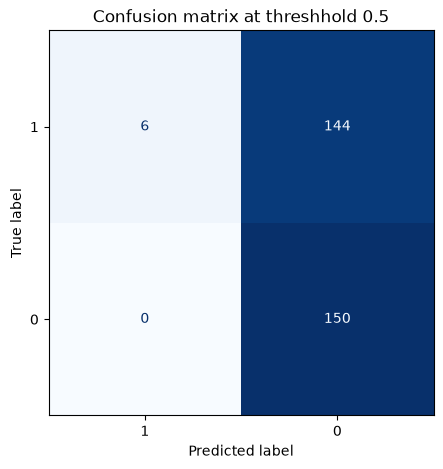

In [223]:
thresholds = [0.1, 0.2, 0.3, 0.5,]
labels = [1, 0]
for t in thresholds:
    new_llama_pred = (df["new_llama_prediction"] > t).astype(int)
    fig, ax = plt.subplots(figsize=(6, 5))
    cm = confusion_matrix(
        y_true,
        new_llama_pred,
        labels=labels
    )
    ConfusionMatrixDisplay(confusion_matrix=cm,  display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix at threshhold {t}")
    plt.show()


The confusion matrix shows that, at the selected threshold of 0.1, 56 questions were incorrectly classified as valid arXiv questions (false positives), while only 4 valid questions were incorrectly classified as invalid (false negatives).

Since I would rather have my RAG system attempt to answer a question than incorrectly reject a valid one, I decided to prioritize **recall over precision**. This trade-off allows the system to accept more potentially relevant questions while minimizing the number of valid questions it rejects.